# 06 — Single-line and multi-line galaxies, and their line combinations

Notebook 01 shows the single-line fraction of the Hα and [O III] emitters. This notebook shows the composition of
the **detected galaxies** as a whole, as a function of redshift from 0.5 to 3.0, with the thresholds in use:
a galaxy is detected when one of its lines inside the grism bandpass (10 000–19 300 Å) exceeds the primary threshold
1.5×10⁻¹⁶ erg s⁻¹ cm⁻², and its other in-band lines count as detected above the secondary threshold 6×10⁻¹⁷
(the two-tier rule of the pipeline). At each redshift the detected galaxies are split into single-line galaxies
(from 0 % to x %) and multi-line galaxies (from x % to 100 %); the single-line part is subdivided by the line,
the multi-line part by the combination of detected lines (Hα & [O III] λ5007, [O III] λ5007 & Hβ, ...).

The lines are the seven that matter for the catalog ([O III] λ4363 and [S III] λ6312 are too faint to be detected
and are ignored). The fluxes come from the base catalog, complete above 10⁻¹⁷, read slice by slice
(`base.read_slices`; a few minutes on a login node); the redshift is `redshift_rsd`, the one the pipeline uses for
the bandpass test, in bins of 0.01. No line confusion is applied: these are the true lines of every galaxy.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")      # diffsky imports JAX; keep it off the GPU

import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from romanmock import BaseCatalog, plotting
from romanmock.roman import GRISM_WAVE_RANGE_ANGSTROM as WAVE_RANGE

plotting.use_style()

MOCK = "sdss_feniks_hizels_260710_09_07_2026"                          # version of the diffsky mock
ROOT = f"/global/cfs/cdirs/m4943/Simulations/RomanMocks/{MOCK}"        # products of romanmock for this mock
base = BaseCatalog(f"{ROOT}/base")

F_PRIMARY, F_SECOND = 1.5e-16, 6.0e-17                                 # erg/s/cm^2
Z_RANGE, DZ = (0.5, 3.0), 0.01
LINES = ["Ha", "OIII_5007", "SIII_9532", "SIII_9069", "Hb", "OIII_4959", "OII_3727"]     # brightest to faintest in the mock
LABEL = {"Ha": "Hα", "Hb": "Hβ", "OIII_5007": "[O III] λ5007", "OIII_4959": "[O III] λ4959", "OII_3727": "[O II] λ3727",
         "SIII_9532": "[S III] λ9532", "SIII_9069": "[S III] λ9069"}
rest = np.array([base.line_set.rest_waves[base.line_set.bit(line)] for line in LINES])

z_edges = np.round(np.arange(Z_RANGE[0], Z_RANGE[1] + 1e-9, DZ), 6)
z = 0.5 * (z_edges[1:] + z_edges[:-1])
N_COMBO = 2 ** len(LINES)                                               # combination code: bit i set = line i detected
counts = np.zeros((z_edges.size - 1, N_COMBO), dtype=np.int64)         # detected galaxies per redshift bin and combination
N_LINES = len(LINES)
pair_counts = np.zeros((z_edges.size - 1, N_LINES ** 2), dtype=np.int64)   # multi-line galaxies per bin and (brightest, second) detected line

t0 = time.time()
for data in base.read_slices(["redshift_rsd", *[f"{line}_flux" for line in LINES]], z_range=Z_RANGE):   # one slice at a time
    zg = np.asarray(data["redshift_rsd"], dtype=np.float64)
    flux = np.stack([np.asarray(data[f"{line}_flux"], dtype=np.float64) for line in LINES], axis=1)
    wave = rest[None, :] * (1 + zg[:, None])
    in_band = (wave >= WAVE_RANGE[0]) & (wave < WAVE_RANGE[1])
    detected = np.any(in_band & (flux > F_PRIMARY), axis=1)                                   # a primary line: the galaxy is detected
    lines_on = in_band[detected] & (flux[detected] > F_SECOND)                                # its detected lines (two-tier rule)
    combo = (lines_on << np.arange(len(LINES))[None, :]).sum(axis=1)
    counts += np.histogram2d(zg[detected], combo, bins=(z_edges, np.arange(N_COMBO + 1) - 0.5))[0].astype(np.int64)
    order = np.argsort(-np.where(lines_on, flux[detected], -1.0), axis=1)[:, :2]             # the two brightest detected lines
    is_multi = lines_on.sum(axis=1) >= 2
    pair = order[is_multi, 0] * N_LINES + order[is_multi, 1]
    pair_counts += np.histogram2d(zg[detected][is_multi], pair, bins=(z_edges, np.arange(N_LINES ** 2 + 1) - 0.5))[0].astype(np.int64)
n_det = counts.sum(axis=1)
popcount = np.array([bin(c).count("1") for c in range(N_COMBO)])
print(f"{counts.sum():,} detected galaxies at {Z_RANGE[0]} < z < {Z_RANGE[1]} in {time.time() - t0:.0f} s: "
      f"{counts[:, popcount == 1].sum():,} single-line ({100 * counts[:, popcount == 1].sum() / counts.sum():.1f} %), "
      f"{counts[:, popcount > 1].sum():,} multi-line")

40,580,722 detected galaxies at 0.5 < z < 3.0 in 219 s: 2,177,819 single-line (5.4 %), 38,402,903 multi-line


## Composition of the detected galaxies

Stacked fractions of the detected galaxies per redshift bin. The single-line galaxies are at the bottom, one band per
line (hatched, in the color of the line); the black line is their total, the boundary x between single-line and
multi-line galaxies. Above it the multi-line galaxies, one band per combination of detected lines: the combinations
with Hα in shades of blue, those with [O III] λ5007 but no Hα in shades of orange, the rest in grey. Combinations
that never reach 5 % of the detected galaxies in any redshift bin are grouped into "other".

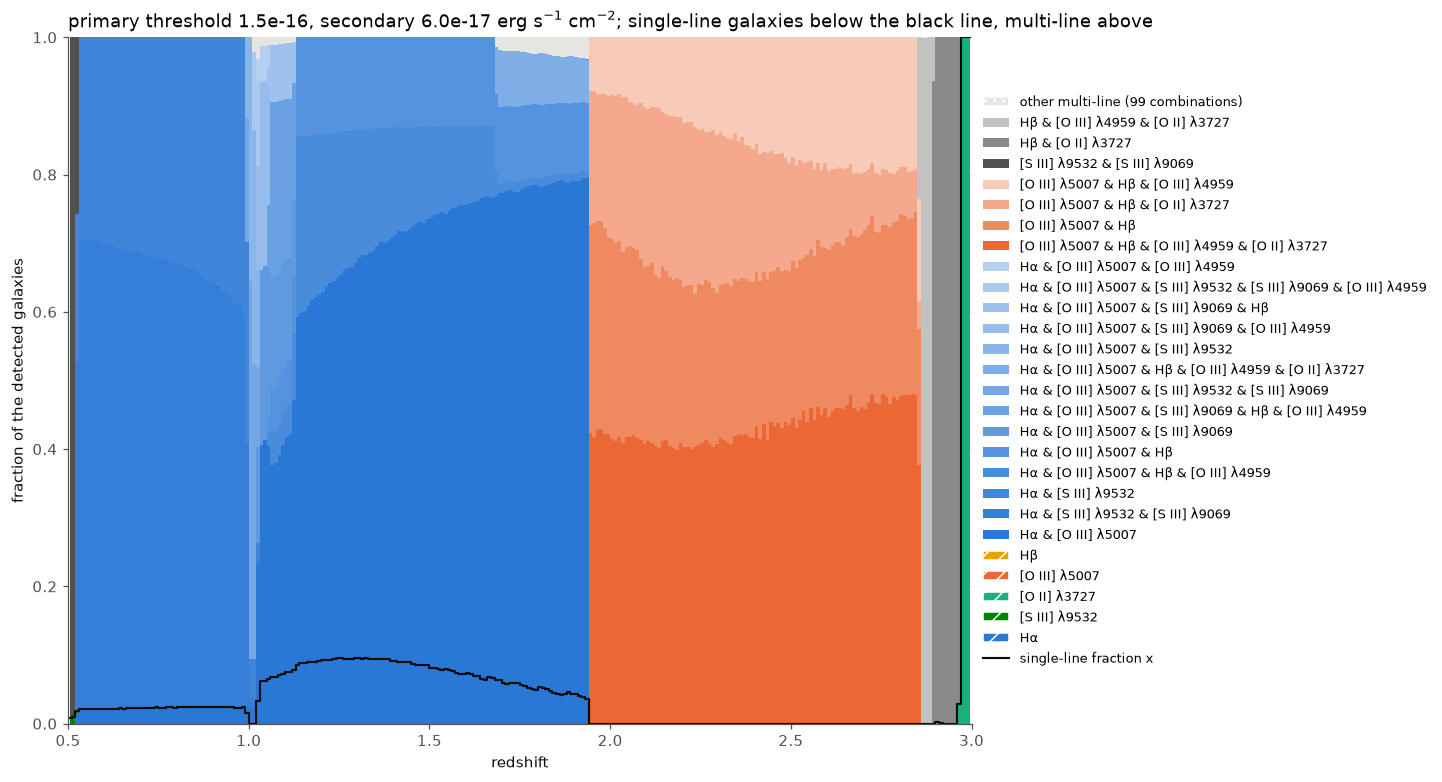

fraction of the detected galaxies at z =           0.60   0.91   1.21   1.50   1.81   2.10   2.50   2.91
detected galaxies per bin of 0.01                  273k   335k   334k   228k   197k    15k     8k     1k
single-line (x)                                   0.021  0.024  0.092  0.082  0.054  0.000  0.000  0.002
  Hα                                              0.021  0.024  0.092  0.082  0.054  0.000  0.000  0.000
  [S III] λ9532                                   0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000
  [O II] λ3727                                    0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000
  [O III] λ5007                                   0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000
  Hβ                                              0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.002
  Hα & [O III] λ5007                              0.000  0.000  0.537  0.655  0.728  0.000  0.000  0.000
  Hα & [S III] λ9532 & [S III] λ9069              0.677

In [3]:
MIN_SHARE = 0.05                                                        # a combination is named when it reaches this share in some redshift bin

def name(c):
    return " & ".join(LABEL[LINES[i]] for i in range(len(LINES)) if c >> i & 1)

def shade(color, t):
    '''Color mixed with white by a fraction t (0: the color, 1: white).'''
    r, g, b = to_rgb(color)
    return (r + (1 - r) * t, g + (1 - g) * t, b + (1 - b) * t)

with np.errstate(invalid="ignore", divide="ignore"):
    share = np.where(n_det[:, None] > 0, counts / n_det[:, None], 0.0)    # fraction of the detected galaxies per bin
single = [c for c in np.argsort(-counts.sum(axis=0)) if popcount[c] == 1 and counts[:, c].sum() > 0]
multi = [c for c in np.argsort(-counts.sum(axis=0)) if popcount[c] > 1]
major = [c for c in multi if share[:, c].max() >= MIN_SHARE]
other = [c for c in multi if c not in major]

group = lambda c: 0 if c & 1 else (1 if c >> LINES.index("OIII_5007") & 1 else 2)     # 0: with Hα, 1: with [O III] 5007, 2: the rest
base_color = {0: plotting.feature_color("Ha"), 1: plotting.feature_color("OIII_5007"), 2: plotting.TEXT_SECONDARY}
bands = []                                                              # (label, color, hatch, fraction per bin), bottom to top
for c in single:
    bands.append((name(c), plotting.feature_color(LINES[int(np.log2(c))]), "//", share[:, c]))
for g in (0, 1, 2):
    members = [c for c in major if group(c) == g]
    for k, c in enumerate(members):
        bands.append((name(c), shade(base_color[g], 0.65 * k / max(len(members) - 1, 1)), None, share[:, c]))
if other:
    bands.append((f"other multi-line ({len(other)} combinations)", plotting.GRID, "..", share[:, other].sum(axis=1)))

fig, ax = plt.subplots(figsize=(13, 7), constrained_layout=True)
bottom = np.zeros(z.size)
for label, color, hatch, frac in bands:
    ax.fill_between(z, bottom, bottom + frac, step="mid", color=color, hatch=hatch, lw=0, edgecolor="white" if hatch else None, label=label)
    bottom = bottom + frac
single_total = share[:, popcount == 1].sum(axis=1)
ax.step(z, single_total, where="mid", color=plotting.TEXT_PRIMARY, lw=1.4)
ax.set_xlim(Z_RANGE)
ax.set_ylim(0, 1)
ax.set_xlabel("redshift")
ax.set_ylabel("fraction of the detected galaxies")
ax.set_title(f"primary threshold {F_PRIMARY:.1e}, secondary {F_SECOND:.1e} erg s$^{{-1}}$ cm$^{{-2}}$; "
             "single-line galaxies below the black line, multi-line above", loc="left")
handles = [Patch(facecolor=color, hatch=hatch, edgecolor="white" if hatch else "none", label=label) for label, color, hatch, _ in bands][::-1]
handles.append(Line2D([], [], color=plotting.TEXT_PRIMARY, lw=1.4, label="single-line fraction x"))
ax.legend(handles=handles, frameon=False, fontsize=8.5, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.show()

at = np.searchsorted(z, [0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.5, 2.9])
print(f"{'fraction of the detected galaxies at z =':<48s}" + "".join(f"{v:7.2f}" for v in z[at]))
print(f"{'detected galaxies per bin of ' + f'{DZ}':<48s}" + "".join(f"{n_det[j] / 1e3:6.0f}k" for j in at))
print(f"{'single-line (x)':<48s}" + "".join(f"{single_total[j]:7.3f}" for j in at))
for label, _, _, frac in bands:
    print(f"  {label:<46s}" + "".join(f"{frac[j]:7.3f}" for j in at))

## Single-line against multi-line, and the breakdown of each

The same counts in three panels. Left: the detected galaxies split into single-line (0 to x %) and multi-line
(x % to 100 %). Middle: the single-line galaxies alone, broken down by line and normalised to 100 % of the
single-line galaxies. Right: the multi-line galaxies alone, broken down by their **two brightest detected lines** (brightest first:
a galaxy with Hα, [S III] λ9532 and [S III] λ9069 detected counts as Hα & [S III] λ9532 when those two are the
brightest), normalised to 100 % of the multi-line galaxies. In the middle and right panels every line or pair that
reaches 1 % of its group in some redshift bin is named; the rest are grouped into "other". Bins with fewer than 10
galaxies in the group are left blank: beyond z = 1.94 the mock has almost no single-line galaxies (25 in total,
see notebook 05), so the middle panel is empty there.

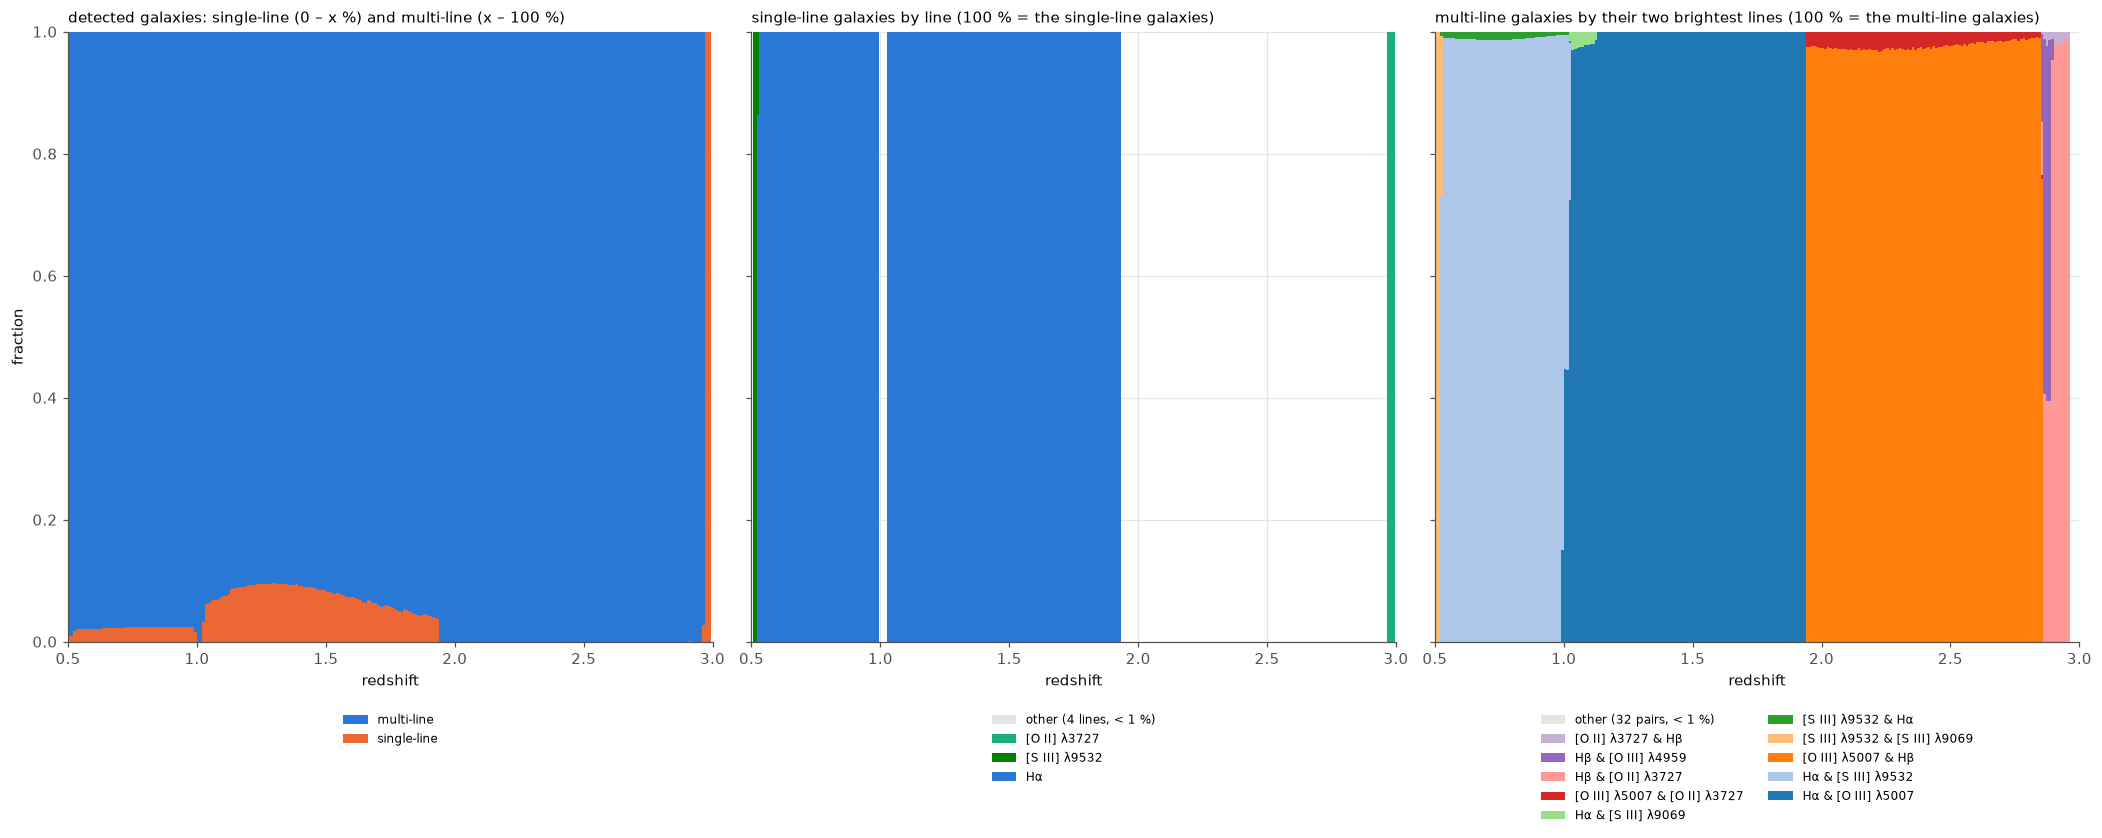

fraction of the single-line galaxies at z =            0.60   0.91   1.21   1.50   1.81   2.10   2.50   2.91
  Hα                                                  1.000  1.000  1.000  1.000  1.000    nan    nan    nan
  [S III] λ9532                                       0.000  0.000  0.000  0.000  0.000    nan    nan    nan
  [O II] λ3727                                        0.000  0.000  0.000  0.000  0.000    nan    nan    nan
  other (4 lines, < 1 %)                              0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000
fraction of the multi-line galaxies at z =             0.60   0.91   1.21   1.50   1.81   2.10   2.50   2.91
  Hα & [O III] λ5007                                  0.000  0.000  1.000  1.000  1.000  0.000  0.000  0.000
  Hα & [S III] λ9532                                  0.988  0.991  0.000  0.000  0.000  0.000  0.000  0.000
  [O III] λ5007 & Hβ                                  0.000  0.000  0.000  0.000  0.000  0.969  0.976  0.000
  [S III] λ9532 & [

In [4]:
MIN_PART = 0.01                                                         # a line or combination is named when it reaches this share of its group in some bin
MIN_GROUP = 10                                                          # bins with fewer galaxies in the group are left blank

def breakdown(hist, codes, label_of, min_part):
    '''Fractions of the galaxies of `codes` per bin: one per code that reaches `min_part` in some bin, and the rest together.'''
    n = hist[:, codes].sum(axis=1)
    with np.errstate(invalid="ignore", divide="ignore"):
        frac = {c: np.where(n >= MIN_GROUP, hist[:, c] / n, np.nan) for c in codes}
    named = [c for c in sorted(codes, key=lambda c: -hist[:, c].sum()) if np.nanmax(frac[c]) >= min_part]
    rest = [c for c in codes if c not in named]
    return [(label_of(c), frac[c]) for c in named], (np.nansum([frac[c] for c in rest], axis=0) if rest else None, len(rest))

def stack(ax, parts, colors, hatches=None):
    bottom = np.zeros(z.size)
    for k, ((label, frac), color) in enumerate(zip(parts, colors)):
        hatch = hatches[k] if hatches else None
        ax.fill_between(z, bottom, bottom + frac, step="mid", color=color, hatch=hatch, lw=0,
                        edgecolor="white" if hatch else None, label=label)
        bottom = bottom + frac
    ax.set_xlim(Z_RANGE)
    ax.set_ylim(0, 1)
    ax.set_xlabel("redshift")
    ax.legend(handles=ax.get_legend_handles_labels()[0][::-1], frameon=False, fontsize=8, loc="upper center",
              bbox_to_anchor=(0.5, -0.1), ncol=1 if len(parts) <= 8 else 2)

single_codes = [c for c in range(N_COMBO) if popcount[c] == 1]
pair_codes = [i * N_LINES + j for i in range(N_LINES) for j in range(N_LINES) if i != j]
pair_name = lambda c: f"{LABEL[LINES[c // N_LINES]]} & {LABEL[LINES[c % N_LINES]]}"       # brightest line first
parts_single, (rest_single, n_rest_single) = breakdown(counts, single_codes, name, MIN_PART)
parts_multi, (rest_multi, n_rest_multi) = breakdown(pair_counts, pair_codes, pair_name, MIN_PART)
if rest_single is not None:
    parts_single.append((f"other ({n_rest_single} lines, < {100 * MIN_PART:.0f} %)", rest_single))
if rest_multi is not None:
    parts_multi.append((f"other ({n_rest_multi} pairs, < {100 * MIN_PART:.0f} %)", rest_multi))

fig, axes = plt.subplots(1, 3, figsize=(19, 7.5), sharey=True, constrained_layout=True)
stack(axes[0], [("single-line", single_total), ("multi-line", 1 - single_total)], [plotting.CATEGORICAL[1], plotting.CATEGORICAL[0]])
axes[0].set_title("detected galaxies: single-line (0 – x %) and multi-line (x – 100 %)", loc="left", fontsize=10)
axes[0].set_ylabel("fraction")
line_of = {LABEL[l]: l for l in LINES}
colors = [plotting.feature_color(line_of[lbl]) if lbl in line_of else plotting.GRID for lbl, _ in parts_single]
stack(axes[1], parts_single, colors, hatches=["//" if lbl in line_of else ".." for lbl, _ in parts_single])
axes[1].set_title("single-line galaxies by line (100 % = the single-line galaxies)", loc="left", fontsize=10)
palette = [plt.get_cmap("tab20")(k) for k in range(20)] + [plt.get_cmap("tab20b")(k) for k in range(20)]
colors = [palette[k % len(palette)] for k in range(len(parts_multi))]
if rest_multi is not None:
    colors[-1] = plotting.GRID
stack(axes[2], parts_multi, colors)
axes[2].set_title("multi-line galaxies by their two brightest lines (100 % = the multi-line galaxies)", loc="left", fontsize=10)
plt.show()

print(f"{'fraction of the single-line galaxies at z =':<52s}" + "".join(f"{v:7.2f}" for v in z[at]))
for label, frac in parts_single:
    print(f"  {label:<50s}" + "".join(f"{frac[j]:7.3f}" for j in at))
print(f"{'fraction of the multi-line galaxies at z =':<52s}" + "".join(f"{v:7.2f}" for v in z[at]))
for label, frac in parts_multi:
    print(f"  {label:<50s}" + "".join(f"{frac[j]:7.3f}" for j in at))